Подключение библиотек

In [117]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

Начальные данные:\
P = 90 мин\
tsh = 35 мин\
tsun = 55 мин\
tau = 30 мин\
Teq = Tsun = +80 на свету\
Teq = Tsh = -40 в тени\
В момент t=0  спутник выходит из тени на свет с
T = T0 = -20\
Найти T(t) за 5 витков и построить график

In [120]:
tau, Teq, Tstart = sp.symbols('tau Teq Tstart', positive=True)
#Время на 1 участке
s = sp.Symbol('s', real=True, nonnegative=True)
T = sp.Function('T')

ДУ

In [123]:
ode_T = sp.Eq(sp.diff(T(s), s) + T(s)/tau, Teq/tau)
sp.pprint(ode_T)

d          T(s)   Teq
──(T(s)) + ──── = ───
ds          τ      τ 


Симольное решение

In [126]:
sol_T = sp.dsolve(ode_T, ics={T(0): Tstart})
T_expr = sp.simplify(sol_T.rhs)
print("T(s) = \n\n")
sp.pprint(T_expr)

T(s) = 


⎛     s               ⎞  -s 
⎜     ─               ⎟  ───
⎜     τ               ⎟   τ 
⎝Teq⋅ℯ  - Teq + Tstart⎠⋅ℯ   


Параметры

In [174]:
P = 90.0
t_sh = 35.0
t_sun = 55.0
tau_val = 30.0
T_sun = 80.0
T_sh = -40.0
T0 = -20.0
n_orbits = 5

Общая функция температуры

In [177]:
T_func = sp.lambdify((s, Tstart, Teq, tau), T_expr, 'numpy')

Разбиаем на солнечный/темный участок

In [180]:
t_all = []
T_all = []

t_global = 0.0
T_start = T0

points_per_segment = 200
for orbit in range(n_orbits):
    # Участок света
    s_sun = np.linspace(0, t_sun, points_per_segment)
    T_sun_seg = T_func(s_sun, T_start, T_sun, tau_val)
    t_sun_global = t_global + s_sun

    t_all.extend(t_sun_global)
    T_all.extend(T_sun_seg)

    T_end_sun = T_sun_seg[-1]
    
    t_global += t_sun

    # Участок тени
    s_sh = np.linspace(0, t_sh, points_per_segment)
    T_sh_seg = T_func(s_sh, T_end_sun, T_sh, tau_val)
    t_sh_global = t_global + s_sh

    t_all.extend(t_sh_global)
    T_all.extend(T_sh_seg)

    T_end_sh = T_sh_seg[-1]

    T_start = T_end_sh

    t_global += t_sh

t_all = np.array(t_all)
T_all = np.array(T_all)

In [ ]:
Построение графика

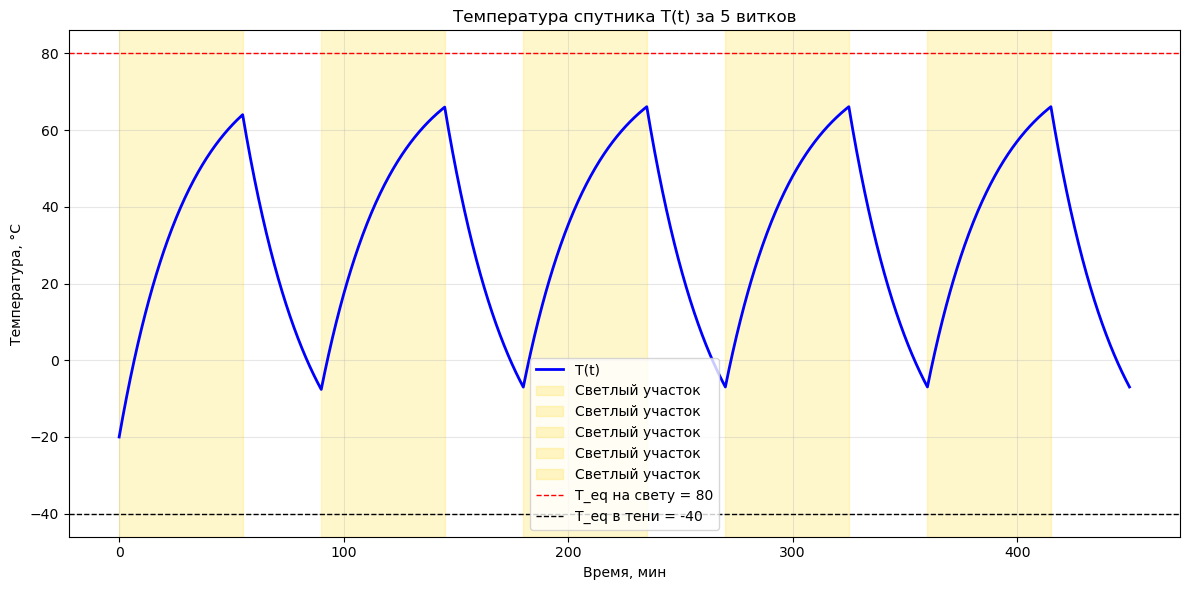

In [182]:
plt.figure(figsize=(12, 6))
plt.plot(t_all, T_all, label='T(t)', color='blue', lw=2)

for k in range(n_orbits):
    t1 = k * P
    t2 = k * P + t_sun
    plt.axvspan(t1, t2, color='gold', alpha=0.2,label='Светлый участок')

plt.axhline(T_sun, color='red', ls='--', lw=1, label='T_eq на свету = 80')
plt.axhline(T_sh, color='black', ls='--', lw=1, label='T_eq в тени = -40')
plt.title('Температура спутника T(t) за 5 витков')
plt.xlabel('Время, мин')
plt.ylabel('Температура, °C')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [186]:
print("Температура в конце каждого витка:\n")
T_start = T0
for orbit in range(1, n_orbits + 1):
    T_after_sun = T_segment(t_sun, T_start, T_sun, tau_val)
    T_after_shadow = T_segment(t_sh, T_after_sun, T_sh, tau_val)
    print(f"Виток {orbit}: T = {T_after_shadow:.3f} °C")
    T_start = T_after_shadow

Температура в конце каждого витка:

Виток 1: T = -7.610 °C
Виток 2: T = -6.993 °C
Виток 3: T = -6.963 °C
Виток 4: T = -6.961 °C
Виток 5: T = -6.961 °C
